# Tópico 2, Hands-On 3: Pêndulo simples e princípio variacional (CAP-422)
Objetivo: deduzir e simular a equação do pêndulo e avaliar a aproximação de pequenos ângulos.
Rode célula por célula ou tudo: `python topic02_variational/handson_3_pendulum.py`

In [1]:
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1] if "__file__" in globals() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
OUT = ROOT / "topic02_variational" / "outputs"
OUT.mkdir(exist_ok=True)

import matplotlib

if "get_ipython" not in globals():  # como script; no notebook as figuras aparecem na célula
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

from cap422.dynamics import (integrate, pendulum_energy, pendulum_rhs, period_exact,
                             period_measured, period_small_angle)
from cap422.variational import action, euler_lagrange, euler_lagrange_with_rayleigh

## 3.1 O sistema
Massa m presa por uma haste rígida sem massa de comprimento ℓ, em um campo gravitacional g.
A única coordenada generalizada é o ângulo θ(t) medido a partir da vertical (θ = 0 é a
posição mais baixa). A massa está sobre um arco de raio ℓ, então a velocidade é v = ℓ θ'.
A altura em relação ao ponto mais baixo é h = ℓ (1 − cos θ).

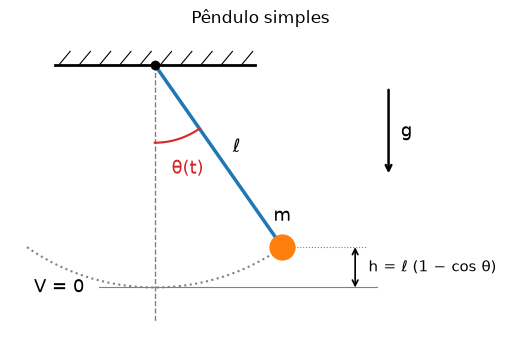

In [2]:
th_d = np.radians(35)  # ângulo usado só no desenho; comprimento desenhado = 1
px, py = np.sin(th_d), -np.cos(th_d)
fig, ax = plt.subplots(figsize=(5.4, 4.4))
ax.plot([-0.45, 0.45], [0, 0], color="k", lw=2)  # suporte
for xh in np.linspace(-0.43, 0.39, 10):
    ax.plot([xh, xh + 0.05], [0, 0.06], color="k", lw=0.8)
ax.plot([0, 0], [0, -1.15], "--", color="gray", lw=1)  # vertical
arco = np.linspace(-th_d, th_d, 100)  # caminho da massa
ax.plot(np.sin(arco), -np.cos(arco), ":", color="gray")
ax.plot([0, px], [0, py], color="C0", lw=2.5)  # haste
ax.scatter([0], [0], color="k", zorder=3)
ax.scatter([px], [py], s=320, color="C1", zorder=3)
ang = np.linspace(0, th_d, 50)
ax.plot(0.35 * np.sin(ang), -0.35 * np.cos(ang), color="C3", lw=1.5)
centro = dict(ha="center", va="center", fontsize=13)
ax.text(0.49 * np.sin(th_d / 2), -0.49 * np.cos(th_d / 2), "θ(t)", color="C3", **centro)
ax.text(px / 2 + 0.08, py / 2 + 0.04, "ℓ", **centro)
ax.text(px, py + 0.14, "m", **centro)
ax.annotate("", xy=(1.05, -0.5), xytext=(1.05, -0.1), arrowprops=dict(arrowstyle="->", lw=1.8))
ax.text(1.13, -0.3, "g", **centro)
ax.plot([-0.25, 1.0], [-1, -1], color="gray", lw=0.8)  # nível de referência do potencial
ax.text(-0.43, -1.0, "V = 0", **centro)
ax.plot([px, 0.95], [py, py], color="gray", lw=0.8, ls=":")
ax.annotate("", xy=(0.9, py), xytext=(0.9, -1), arrowprops=dict(arrowstyle="<->", lw=1.2, shrinkA=0, shrinkB=0))
ax.text(0.96, (py - 1) / 2, "h = ℓ (1 − cos θ)", ha="left", va="center", fontsize=11)
ax.set(xlim=(-0.65, 1.6), ylim=(-1.2, 0.15), title="Pêndulo simples")
ax.set_aspect("equal")
ax.axis("off")
fig.tight_layout()
fig.savefig(OUT / "h3_desenho.png", dpi=150)

## 3.2 T, V, L e a ação
T = ½ m ℓ² θ'²,   V = m g ℓ (1 − cos θ)  (zero embaixo),   L = T − V,   S[θ] = ∫ L dt.

In [3]:
t = sp.Symbol("t", real=True)
m, l, g = sp.symbols("m ell g", positive=True)
th = sp.Function("theta")(t)
thp = sp.diff(th, t)

T = sp.Rational(1, 2) * m * l**2 * thp**2
V = m * g * l * (1 - sp.cos(th))
L = T - V
t0, t1 = sp.symbols("t0 t1")
print("3.2) T =", T)
print("     V =", V)
print("     L = T − V =", L)
print("     S[θ] =")
sp.pprint(action(L, t, t0, t1))

3.2) T = ell**2*m*Derivative(theta(t), t)**2/2
     V = ell*g*m*(1 - cos(theta(t)))
     L = T − V = ell**2*m*Derivative(theta(t), t)**2/2 - ell*g*m*(1 - cos(theta(t)))
     S[θ] =
t₁                                                  
⌠                                                   
⎮  ⎛                 2                          ⎞   
⎮  ⎜   2   ⎛d       ⎞                           ⎟   
⎮  ⎜ell ⋅m⋅⎜──(θ(t))⎟                           ⎟   
⎮  ⎜       ⎝dt      ⎠                           ⎟   
⎮  ⎜────────────────── - ell⋅g⋅m⋅(1 - cos(θ(t)))⎟ dt
⎮  ⎝        2                                   ⎠   
⌡                                                   
t₀                                                  


## 3.3 Euler-Lagrange com SymPy (sem partir da força tangencial de Newton)

In [4]:
el = euler_lagrange(L, th, t)
eq = sp.Eq(sp.simplify(el / (m * l**2)), 0)
print("3.3) Equação de Euler-Lagrange (dividida por m ℓ²):")
sp.pprint(eq)
print("     isolando θ'':", sp.solve(eq, sp.diff(th, t, 2))[0])

3.3) Equação de Euler-Lagrange (dividida por m ℓ²):
 2                         
d           g⋅sin(θ(t))    
───(θ(t)) + ─────────── = 0
  2             ell        
dt                         
     isolando θ'': -g*sin(theta(t))/ell


## 3.4 Pequenos ângulos
Para |θ| pequeno, sen θ ≈ θ, e a equação vira  θ'' + (g/ℓ) θ = 0.
É um oscilador harmônico com **ω0 = √(g/ℓ)** e **T0 = 2π √(ℓ/g)**, independente da amplitude.

In [5]:
theta_s = sp.Symbol("theta")
print("3.4) sen θ ≈", sp.series(sp.sin(theta_s), theta_s, 0, 4).removeO())
print("     ω0 = √(g/ℓ)  e  T0 = 2π √(ℓ/g)")
G, ELL = 9.81, 1.0
print(f"     com g = {G} m/s² e ℓ = {ELL} m:  ω0 = {np.sqrt(G / ELL):.4f} rad/s, T0 = {period_small_angle(G, ELL):.4f} s")

3.4) sen θ ≈ -theta**3/6 + theta
     ω0 = √(g/ℓ)  e  T0 = 2π √(ℓ/g)
     com g = 9.81 m/s² e ℓ = 1.0 m:  ω0 = 3.1321 rad/s, T0 = 2.0061 s


## 3.5 e 3.6 Simulação: não linear × linearizada (5°, 30°, 90°, partindo do repouso)

3.6) θ0   T medido   T exato(K)   T0       erro T0 vs T   max|Δθ|(5T0)   desvio E
       5°  2.00702   2.00702    2.00607    -0.05 %         0.071°    4.7e-10
      30°  2.04099   2.04099    2.00607    -1.71 %        15.328°    4.3e-10
      90°  2.36784   2.36784    2.00607   -15.28 %       178.837°    2.5e-10


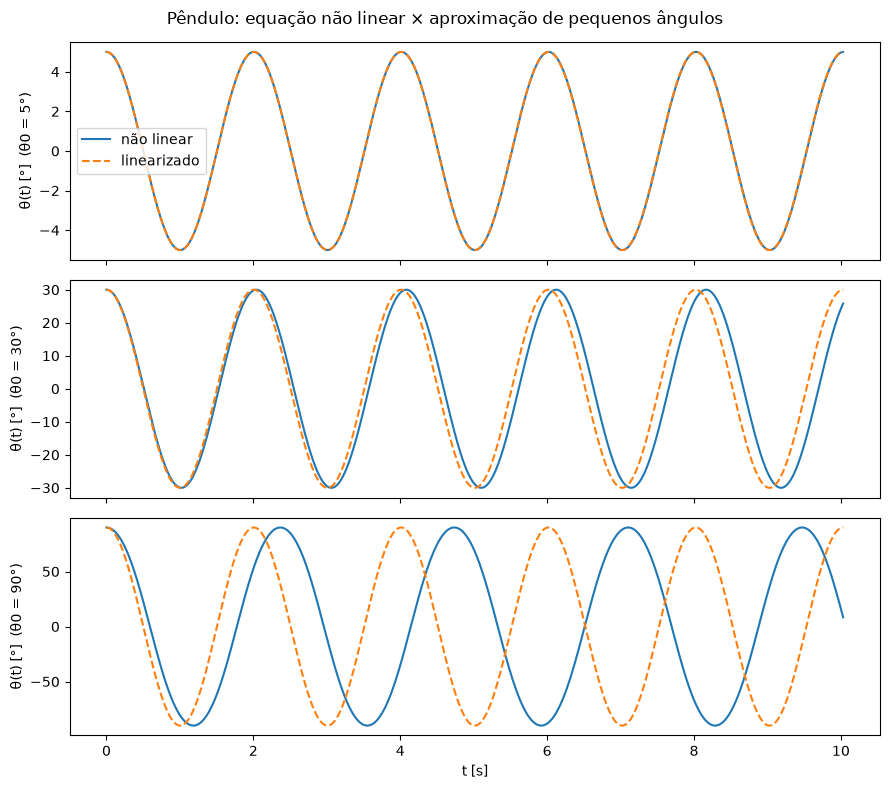

In [6]:
T0 = period_small_angle(G, ELL)
angulos = (5, 30, 90)
t_end = 5 * T0
fig, axs = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
linhas = []
for ax, ang in zip(axs, angulos):
    th0 = np.radians(ang)
    nl = integrate(pendulum_rhs(G, ELL, linear=False), [th0, 0.0], t_end, n=5000)
    li = integrate(pendulum_rhs(G, ELL, linear=True), [th0, 0.0], t_end, n=5000)
    # períodos: medido (nl), exato (elíptica) e pequeno ângulo
    Tn = period_measured(pendulum_rhs(G, ELL), th0, t_end)
    Tex = period_exact(th0, G, ELL)
    err_per = 100 * (T0 - Tn) / Tn
    # erro de trajetória e energia
    dif = np.degrees(np.abs(nl.y[0] - li.y[0]))
    En = pendulum_energy(nl.y[0], nl.y[1], 1.0, G, ELL)
    drift = np.max(np.abs(En - En[0])) / En[0]
    linhas.append((ang, Tn, Tex, err_per, dif.max(), drift))
    ax.plot(nl.t, np.degrees(nl.y[0]), label="não linear")
    ax.plot(li.t, np.degrees(li.y[0]), "--", label="linearizado")
    ax.set_ylabel(f"θ(t) [°]  (θ0 = {ang}°)")
axs[0].legend(); axs[-1].set_xlabel("t [s]")
fig.suptitle("Pêndulo: equação não linear × aproximação de pequenos ângulos")
fig.tight_layout()
fig.savefig(OUT / "h3_trajetorias.png", dpi=150)

print("3.6) θ0   T medido   T exato(K)   T0       erro T0 vs T   max|Δθ|(5T0)   desvio E")
for ang, Tn, Tex, err, dmax, drift in linhas:
    print(f"     {ang:>3}°  {Tn:.5f}   {Tex:.5f}    {T0:.5f}   {err:+6.2f} %      {dmax:8.3f}°    {drift:.1e}")

**Leitura da tabela acima:**
- O período medido bate com o período exato (integral elíptica K) até a 5ª casa decimal: a simulação está correta.
- Em 5° a diferença entre as trajetórias é minúscula e o erro do período fica em torno de 0.05%.
- Em 30° o linearizado já adianta visivelmente em poucos ciclos (o período real é ~1.7% maior que T0).
- Em 90° a aproximação falha: o período real é ~18% maior que T0, e a trajetória linearizada
  fica totalmente fora de fase depois de poucos ciclos.
- Cuidado com a referência da porcentagem: a coluna "erro T0 vs T" é (T0 − T)/T. Em 90° ela dá −15.3%,
  ou seja, T0 fica 15.3% abaixo do período real, o que equivale a T ser 18.0% maior que T0.
- A energia mecânica do pêndulo ideal não linear se conserva até o erro numérico (~1e-10).

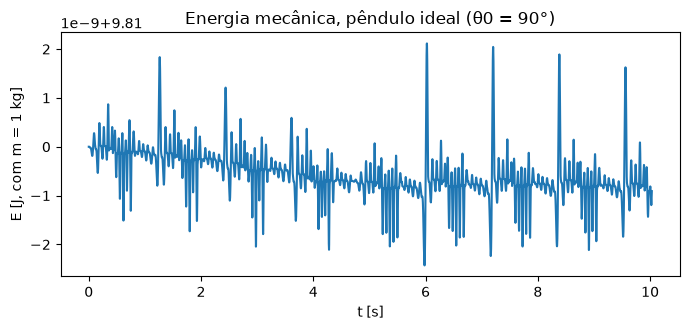

In [7]:
th0 = np.radians(90)
nl = integrate(pendulum_rhs(G, ELL), [th0, 0.0], t_end, n=5000)
En = pendulum_energy(nl.y[0], nl.y[1], 1.0, G, ELL)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(nl.t, En)
ax.set(xlabel="t [s]", ylabel="E [J, com m = 1 kg]", title="Energia mecânica, pêndulo ideal (θ0 = 90°)")
fig.tight_layout()
fig.savefig(OUT / "h3_energia.png", dpi=150)

## 3.7 Simetria e conservação (Noether)
A Lagrangiana L(θ, θ') **não depende explicitamente do tempo**: L é invariante por translação
no tempo, t → t + c. O teorema de Noether associa essa simetria à conservação da quantidade
H = θ' ∂L/∂θ' − L = T + V, que é a **energia mecânica**. (A simetria de rotação não existe aqui:
a gravidade fixa uma direção, então o momento angular em torno do pivô não se conserva.)

## 3.8 Opcional: com atrito de Rayleigh
Com R = ½ b θ'², a equação fica  m ℓ² θ'' + b θ' + m g ℓ sen θ = 0. A energia deixa de se
conservar e passa a obedecer  dE/dt = −b θ'² ≤ 0.

3.8) EL com Rayleigh: Eq(b*Derivative(theta(t), t) + ell**2*m*Derivative(theta(t), (t, 2)) + ell*g*m*sin(theta(t)), 0)
     erro máximo de dE/dt contra −b θ'²: 4.08e-04


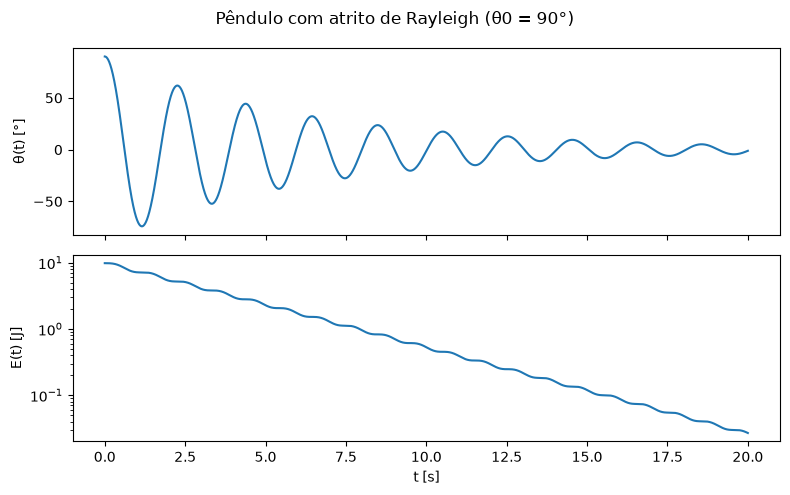

In [8]:
bcoef = 0.3  # kg·m²/s
mm = 1.0
Rr = sp.Rational(1, 2) * sp.Symbol("b", positive=True) * thp**2
print("3.8) EL com Rayleigh:", sp.Eq(euler_lagrange_with_rayleigh(L, th, t, Rr), 0))

gam = bcoef / (mm * ELL**2)  # θ'' + gam θ' + (g/ℓ) sen θ = 0
amort = integrate(pendulum_rhs(G, ELL, damping=gam), [np.radians(90), 0.0], 20.0, n=4000)
Ea = pendulum_energy(amort.y[0], amort.y[1], mm, G, ELL)
# checa dE/dt = −b θ'²:  dE/dt numérico × fórmula
dEdt = np.gradient(Ea, amort.t)
formula = -bcoef * amort.y[1] ** 2
print(f"     erro máximo de dE/dt contra −b θ'²: {np.max(np.abs(dEdt - formula)):.2e}")
fig, axs = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
axs[0].plot(amort.t, np.degrees(amort.y[0])); axs[0].set_ylabel("θ(t) [°]")
axs[1].semilogy(amort.t, Ea); axs[1].set_ylabel("E(t) [J]"); axs[1].set_xlabel("t [s]")
fig.suptitle("Pêndulo com atrito de Rayleigh (θ0 = 90°)")
fig.tight_layout()
fig.savefig(OUT / "h3_amortecido.png", dpi=150)